# SP-LIME run explanations

Select three representative run-start explanations from all stored sample runs.

Move to the repository root before importing project modules.

In [1]:
from pathlib import Path

%cd ../..

d:\User Installed Folders\Master Thesis


Load the agent and initialize a controller.

In [2]:
from stable_baselines3 import SAC

from Explanations.Lime.lime import LimeExplainer
from Explanations.Lime.lime_model import RunValueClass
from Explanations.Lime.peragentcontroller import PerAgentController
from Explanations.Lime.sp_lime import (
    load_run_candidates,
    select_run_explanations,
)
from Simulation.Auxilaries.sim_config import sim_config

model_path = Path("sac_ship_07_0_1.6m.zip")
model = SAC.load(model_path)

pac = PerAgentController(sim_config, model)
pac.new_training_instance()
lime = LimeExplainer(pac)

d:\Uni Programs\Python\Lib\site-packages\stable_baselines3\common\buffers.py:607: UserWarning: This system does not have apparently enough memory to store the complete replay buffer 2.99GB > 2.63GB
  warnings.warn(


Load one candidate for each stored run. The candidate state is reconstructed from its scenario start, so the step logs are not required.

In [3]:
samples_path = Path("Explanations/Samples")
candidates = load_run_candidates(samples_path, sim_config)
print(f"Loaded {len(candidates)} run candidates.")

Loaded 73 run candidates.


Select `k = 5` explanations for run stepcount. Each run is explained with `num_samples = 100` local LIME perturbations.
Each explanation only counts for its top `selection_num_features  2` features.

In [4]:
selected = select_run_explanations(
    lime,
    candidates,
    RunValueClass.REWARD_DELTA,
    k=5,
    num_samples=100,
    explanation_num_features=8, # Show all features.
    selection_num_features=2,
    discretize_continuous=False,
)

print([result.id for result in selected])

['run0061', 'run0056', 'run0050', 'run0063', 'run0072']


Inspect the selected explanations and their associated scenario contexts.

run0061: start state = [ 0.892       0.87196297 -0.31281255 -0.94981488  0.          0.
  0.31105548 -0.892     ]


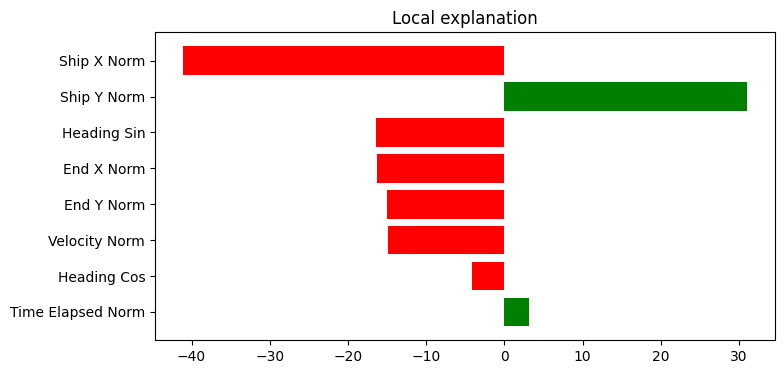

run0056: start state = [-0.892       0.65154351  0.80065253 -0.59912898  0.          0.
  0.892      -0.68342524]


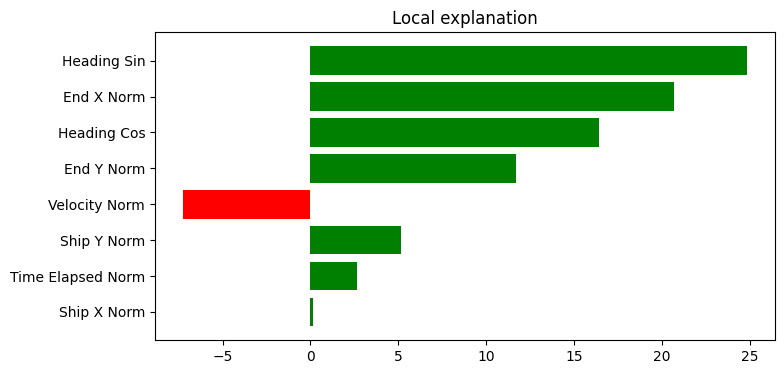

run0050: start state = [-0.892      -0.18525332  0.89099747 -0.45400827  0.          0.
  0.49500009 -0.892     ]


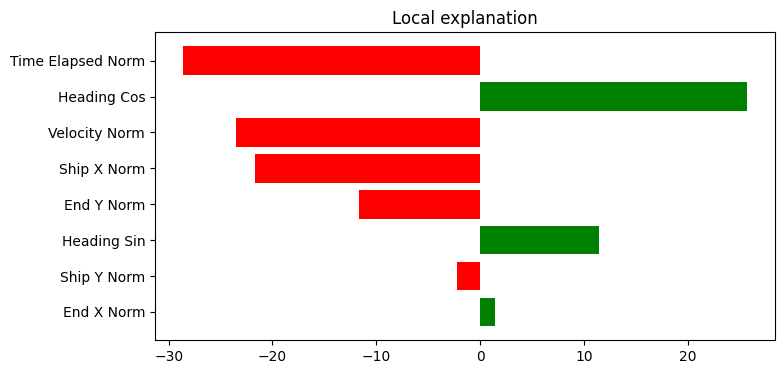

run0063: start state = [ 0.86562667  0.63916723 -0.81631885 -0.57760153  0.          0.
 -0.84173188 -0.56890595]


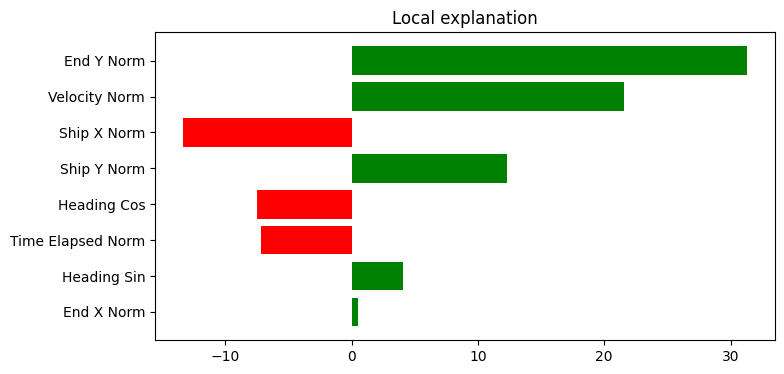

run0072: start state = [ 0.187213   -0.892       0.24865927  0.96859102  0.          0.
  0.64520624  0.892     ]


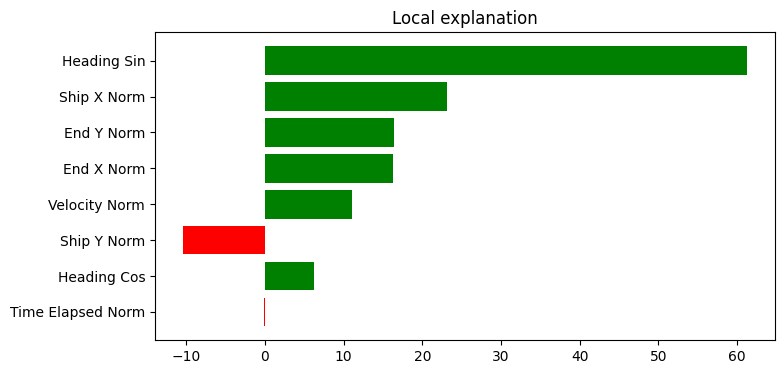

In [5]:
import matplotlib.pyplot as plt
from IPython.display import display

for result in selected:
    print(f"{result.id}: start state = {result.state}")
    figure = result.explanation.as_pyplot_figure(figsize=(8, 4))
    display(figure)
    plt.close(figure)